# Strip waveguide 90° bend
This notebook contains code that simulates and optimizes 90-degree bend of strip waveguide using **Lumerical FDTD** solver and **lumapi** interface. \
The objective is to optimize geometry to achieve low-loss bend in specified footrpint.

It is based on:
- https://www.flexcompute.com/tidy3d/examples/notebooks/SbendCMAES
- https://opg.optica.org/oe/fulltext.cfm?uri=oe-31-26-43850

In [1]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

# Standard library imports
from datetime import datetime
import math
import pickle

# Third-party imports
import cma
import gdsfactory as gf
from gdsfactory.gpdk import PDK
from IPython.display import display
import lumapi as lma
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [2]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [3]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                   | Description                                                                   | Example                |
| :-------------------------- | :-----------------------------------------------------------------------------| :--------------------- |
| **wavelength_center**       | Wavelength for which simulation will be done.                                 | `1.55*um`              |
| **wavelength_span**         | Span of the wavelength for which simulation will be done.                     | `0.14*um`              |
| **bend_size**               | Size of the bend.                                                             | `15*um`                |
| **core_thickness**          | Thickness of the strip waveguide core.                                        | `220*nm`               |
| **core_width**              | Width of the strip waveguide core.                                            | `500*nm`               |
| **bottom_clad_thickness**   | Thickness of the bottom cladding layer.                                       | `3*um`                 |
| **top_clad_thickness**      | Thickness of the top cladding layer.                                          | `2*um`                 |
| **base_core_material**      | Material of strip waveguide core as defined in Lumerical's materials library. | `Si (Silicon) - Palik` |
| **base_clad_material**      | Material of strip waveguide clad as defined in Lumerical's materials library. | `SiO2 (Glass) - Palik` |
| **base_substrate_material** | Material of substrate as defined in Lumerical's materials library.            | `Si (Silicon) - Palik` |

In [4]:
# Si/SiO2 430x220nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

bend_size = 4*um

core_thickness = 220*nm
core_width = 430*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si (Silicon) - Palik"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [5]:
# Si3N4/SiO2 1000x360nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

bend_size = 15*um

core_thickness = 360*nm
core_width = 1000*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si3N4 (Silicon Nitride) - Luke"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [6]:
# Pre-calculate parameters for experiment

experiment_name = (
    f"{base_core_material.split()[0].lower()}_"
    f"w{int(core_width / nm)}nm_"
    f"h{int(core_thickness / nm)}nm_"
    f"90bendGA_"
    f"s{int(bend_size / um)}um"
)

field_intensity_log_decay = -6

ports_offset = bend_size/20
initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

initial_fdtd_height = initial_ports_height + 2*wavelength_center
initial_fdtd_length = bend_size + 2*wavelength_center + ports_offset + initial_ports_width
initial_fdtd_width = bend_size + 2*wavelength_center + ports_offset + initial_ports_width

frequency_center = C / wavelength_center

In [7]:
# Get solver
solver = lma.FDTD(hide=False)

In [8]:
# Helpers

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

def print_summary(solver):
    simulation_setup_summary = f'''
Simulation region size:
FDTD:x_span = {solver.getnamed("FDTD", "x span")*1e6:.3f} µm
FDTD:y_span = {solver.getnamed("FDTD", "y span")*1e6:.3f} µm
FDTD:z_span = {solver.getnamed("FDTD", "z span")*1e6:.3f} µm

Boundry conditions:
FDTD:x_min_bc = {solver.getnamed("FDTD", "x min bc")}
FDTD:x_max_bc = {solver.getnamed("FDTD", "x max bc")}
FDTD:y_min_bc = {solver.getnamed("FDTD", "y min bc")}
FDTD:y_max_bc = {solver.getnamed("FDTD", "y max bc")}
FDTD:z_min_bc = {solver.getnamed("FDTD", "z min bc")}
FDTD:z_max_bc = {solver.getnamed("FDTD", "z max bc")}

Global source:
wavelength_start = {solver.getglobalsource("wavelength start")*1e9:.1f} nm
wavelength_stop = {solver.getglobalsource("wavelength stop")*1e9:.1f} nm
center_wavelength  = {solver.getglobalsource("center wavelength")*1e9:.1f} nm
wavelength_span = {solver.getglobalsource("wavelength span")*1e9:.1f} nm
    '''

    print(simulation_setup_summary)

# Materials

Material fitting is done using Lumerical's built-in utility of multi-coefficient model.

| Parameter            | Expression                            |
| :------------------- | :------------------------------------ |
| **tolerance**        | 0.001 (hardcoded)                     |
| **max coefficients** | 6 (hardcoded)                         |
| **wavelength min**   | wavelength_center - wavelength_span/2 |
| **wavelength max**   | wavelength_center + wavelength_span/2 |

In [9]:
# Materials fitting

def fit_material(material_name):
    wvl_min = wavelength_center - wavelength_span/2
    wvl_max = wavelength_center + wavelength_span/2

    try:
        solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = solver.copymaterial(material_name)
    
    material_params = {
        "tolerance": 0.001,
        "max coefficients": 6,
        "specify fit range": True,
        "wavelength min": wvl_min,
        "wavelength max": wvl_max,
        "name": f"{material_name} Fitted"
    }
    
    solver.setmaterial(material_fitted, material_params)
    
    return f"{material_name} Fitted"

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

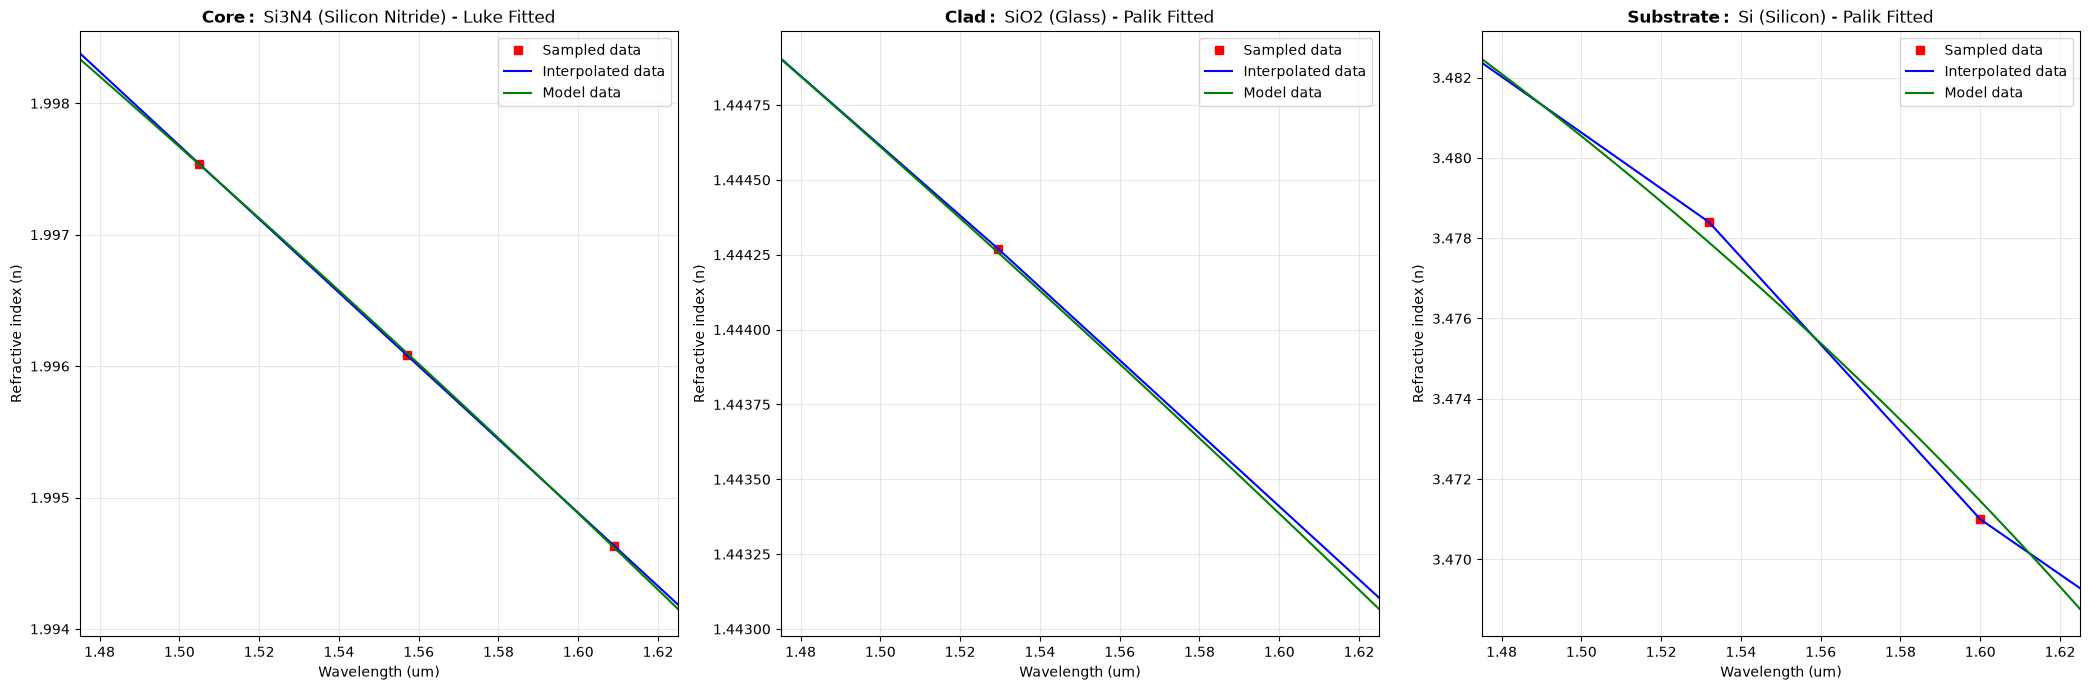

In [10]:
# Materials fit preview

def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = solver.getmaterial(material, "wavelength min")
    wvl_max = solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

# Structures

Once the material properties have been defined, the geometry of the structures under investigation must be specified. \
The following section describes the creation of the substrate slab, cladding layers, and bent waveguide core. \
Additionally, two straight strip waveguides are introduced to serve as connectors to the bent section.

| Parameter               | Expression         |
| :---------------------- | :------------------|
| **substrate_thickness** | 100 µm (hardcoded) |
| **substrate:x_span**    | 100 µm (hardcoded) |
| **substrate:y_span**    | 100 µm (hardcoded) |
| **clad:x_span**         | 100 µm (hardcoded) |
| **clad:y_span**         | 100 µm (hardcoded) |

The bent section is constructed using two Bézier curves, defining the upper and lower contours separately. \
Each curve is defined by four control points, resulting in eight control points in total. \
The first and last control points of both curves are fixed to ensure smooth connections to the waveguide ports. \
The remaining four control points are initially assigned arbitrary positions to create a plausible bend geometry. \
These four points will subsequently serve as optimization variables. \
Since each control point is defined by two coordinates in a 2D Cartesian plane, the geometry is parameterized by a total of eight optimization variables.

In [11]:
# Structures

clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
substrate_thickness = 100*um
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness

def bezier_curve(control_points, num_points=99):
    t = np.linspace(0, 1, num_points)
    curve = np.zeros((num_points, 2))
    n = len(control_points) - 1

    for i in range(n + 1):
        binomial_coeff = math.factorial(n) / (math.factorial(i) * math.factorial(n - i))
        term = binomial_coeff * (1 - t) ** (n - i) * t**i
        curve += np.outer(term, control_points[i])

    return curve

def make_90bend(v):
    p_input = np.array([-bend_size/2, -bend_size/2])
    p_output = np.array([bend_size/2, bend_size/2])

    bend_bot_points = np.array(
        [
            [p_input[0] + core_width/2, p_input[1]], 
            [v[0], v[1]],
            [v[2], v[3]],
            [p_output[0], p_output[1] - core_width/2],
        ]
    )

    bend_top_points = np.array(
        [
            [p_output[0], p_output[1] + core_width/2],
            [v[6], v[7]],
            [v[4], v[5]],
            [p_input[0] - core_width/2, p_input[1]], 
        ]
    )

    bend_bot_curve = bezier_curve(bend_bot_points)
    bend_top_curve = bezier_curve(bend_top_points)
    vertices = np.vstack((bend_bot_curve, bend_top_curve))

    solver.addpoly(
        name="90-bend",
        vertices=vertices,
        z_min=-core_thickness/2,
        z_max=core_thickness/2,
        material=core_material,
    )

# Substrate
remove("substrate")
solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=100*um,
    material=substrate_material,
    alpha=0.8,
)

# Clad
remove("clad")
solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=100*um, z_span=clad_thickness,
    material=clad_material,
    alpha=0.3,
)

p1 = np.array([-bend_size/2 + core_width/2, 0])
p2 = np.array([0, bend_size/2 - core_width/2])
p3 = np.array([-bend_size/2 - core_width/2, 0])
p4 = np.array([0, bend_size/2 + core_width/2])

bend_initial_v = np.array([
    p1[0], p1[1],
    p2[0], p2[1],
    p3[0], p3[1],
    p4[0], p4[1],
])

remove("90-bend")
make_90bend(bend_initial_v)

# Input waveguide
remove("waveguide-in")
solver.addrect(
    name="waveguide-in",
    y_min=-100*um, y_max=-bend_size/2,
    x=-bend_size/2, x_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

# Output waveguide
remove("waveguide-out")
solver.addrect(
    name="waveguide-out",
    x_min=bend_size/2, x_max=100*um,
    y=bend_size/2, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

# Simulation setup

In order to get transmission throught the waveguide bend, **FDTD solver** has been employed. \
All boundry conditions are left with default settings which results in **PML**. 

<img src="assets/stripWaveguide_90bend_initialSimulation.png" width="800">


In [12]:
# Simulation setup

solver.switchtolayout()

# FDTD
remove("FDTD")
solver.addfdtd(
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
    z_span=initial_fdtd_height,
)

solver.setdevice("GPU")
solver.setglobalsource("wavelength start", wavelength_center - wavelength_span/2)
solver.setglobalsource("wavelength stop", wavelength_center + wavelength_span/2)

# Input port
remove("port-in")
solver.addport(
    name="port-in",
    injection_axis="y-axis",
    y=-bend_size/2 - ports_offset, 
    x=-bend_size/2, x_span=initial_ports_width, 
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Output port
remove("port-out")
solver.addport(
    name="port-out",
    injection_axis="x-axis",
    x=bend_size/2 + ports_offset, 
    y=bend_size/2, y_span=initial_ports_width, 
    z=0, z_span=initial_ports_height,
    direction="Backward",
    mode_selection="fundamental TE mode",
);

# Field monitor
remove("field-monitor")
solver.adddftmonitor(
    name="field-monitor",
    monitor_type="2D Z-normal",
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
)

solver.setnamed("FDTD::ports", "override global monitor settings", False)

# Inde monitor
remove("index-monitor")
solver.addindex(
    name="index-monitor",
    monitor_type="2D Z-normal",
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
)

solver.setglobalmonitor("frequency points", 30)

# Global mesh
solver.setnamed("FDTD", "mesh accuracy", 3)


Simulation region size:
FDTD:x_span = 22.850 µm
FDTD:y_span = 22.850 µm
FDTD:z_span = 5.260 µm

Boundry conditions:
FDTD:x_min_bc = PML
FDTD:x_max_bc = PML
FDTD:y_min_bc = PML
FDTD:y_max_bc = PML
FDTD:z_min_bc = PML
FDTD:z_max_bc = PML

Global source:
wavelength_start = 1475.0 nm
wavelength_stop = 1625.0 nm
center_wavelength  = 1550.0 nm
wavelength_span = 150.0 nm
    


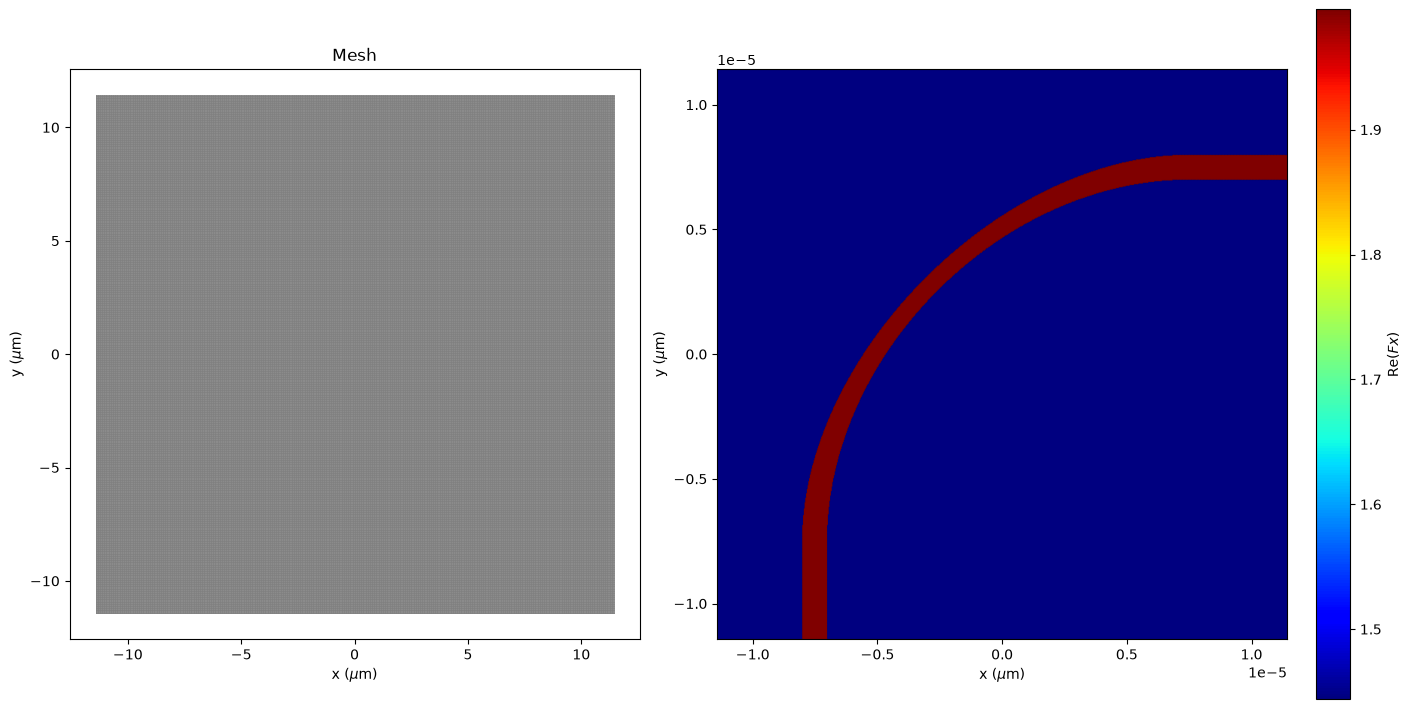

In [13]:
# Simulation preview

index = solver.getresult("index-monitor", "index preview")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, y = np.squeeze(index["x"]), np.squeeze(index["y"])

# Simulation summary
print_summary(solver)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Y = np.meshgrid(x, y, indexing='ij')
ax1.plot(X * 1e6, Y * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Y.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'y ($\mu$m)')
ax1.set_aspect('equal')

# Refractive index
px.plot_field(
    Fx=index_x,
    x=x, y=y,
    ax=ax2,
    scale="lin",
)

plt.show()

experiment_date = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"/tmp/{experiment_name}_{experiment_date}_initialBend.fsp"
solver.save(filename)

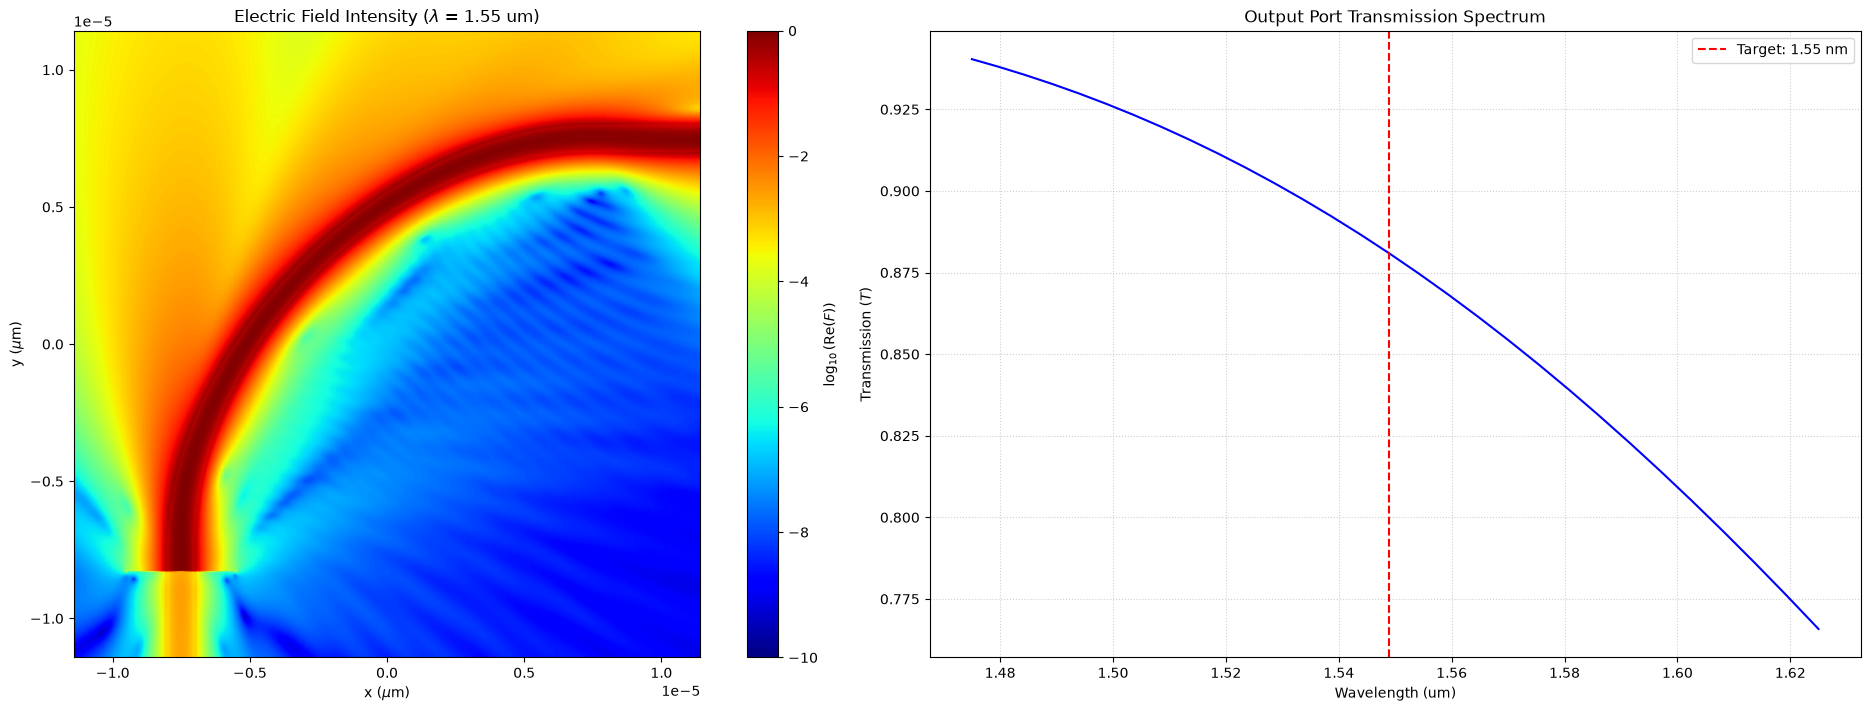

In [14]:
# Initial simulation

# switchtolayout clears solver state so it can be re-run
solver.switchtolayout()
solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 7), constrained_layout=True)

T = solver.getresult("FDTD::ports::port-out", "T")

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T = solver.getresult("FDTD::ports::port-out", "T")
wavelengths = np.squeeze(T["lambda"])
transmission = np.squeeze(T["T"])

ax2.plot(wavelengths*1e6, transmission, color='b')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

# Optimization

In [15]:
def update_90bend(v):
    solver.switchtolayout()
    remove("90-bend")
    make_90bend(v)

def get_mean_transmission_db():
    T = solver.getresult("FDTD::ports::port-out", "T")
    T = np.squeeze(T["T"])
    T_mean = np.mean(T)
    T_db = -10 * np.log10(T_mean + 1e-50)
    print(f"T_db: {T_db}")

    return T_db

def objective_function(vs):
    T = []
    for i, v in enumerate(vs):
        update_90bend(v)
        solver.run()
        T.append(get_mean_transmission_db())

    return T

In [16]:
dim = len(bend_initial_v)
population_size = 10
max_generations = 13
sigma0 = 200*nm
random_seed = 12345

es = cma.CMAEvolutionStrategy(
    bend_initial_v, sigma0, {"popsize": population_size, "maxiter": max_generations, "seed": random_seed}
)

(5_w,10)-aCMA-ES (mu_w=3.2,w_1=45%) in dimension 8 (seed=12345, Wed Nov 25 18:01:53 2026)


In [ ]:
optimization_data = {
    "generations": [],
    "optimizer": None,
}

solver.switchtolayout()
solver.setnamed("field-monitor", "enabled", False)
solver.setnamed("index-monitor", "enabled", False)

gen_idx = 0
while not es.stop():
    solutions = es.ask()
    function_values = objective_function(solutions)
    es.tell(solutions, function_values)

    f_best = es.result.fbest
    x_best = es.result.xbest
    
    # Store history for this generation
    optimization_data["generations"].append({
        "gen": gen_idx,
        "f_best": f_best,
        "x_best": x_best,
    })

    print(f"Generation {gen_idx}: Best function value = {f_best:.3f}")

    gen_idx += 1

# Save the full optimizer state at the end
optimization_data["optimizer"] = es

In [ ]:
# Export results
experiment_date = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"results/{experiment_name}_{experiment_date}.pkl"

with open(filename, "wb") as f:
    pickle.dump(optimization_data, f)

Best loss (0.0471 [dB]) has been obtained in generation (12) for vector:
[-5.98753390e-06 -1.15397411e-06  9.81321770e-07  6.00142642e-06
 -8.60791318e-06  1.89801712e-06 -2.36395508e-07  8.71100602e-06]


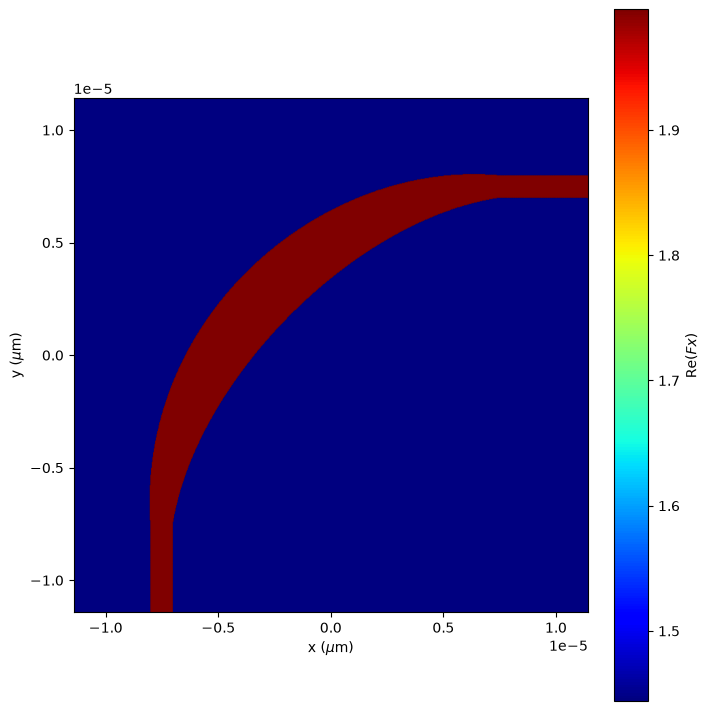

In [20]:
# Best design preview

best_record = min(optimization_data["generations"], key=lambda g: g["f_best"])
best_gen = best_record["gen"]
best_f = best_record["f_best"]
best_x = best_record["x_best"]
print(f"Best loss ({best_f:.4f} [dB]) has been obtained in generation ({best_gen}) for vector:\n{best_x}")

solver.switchtolayout()
solver.setnamed("field-monitor", "enabled", True)
solver.setnamed("index-monitor", "enabled", True)
update_90bend(best_x)

index = solver.getresult("index-monitor", "index preview")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, y = np.squeeze(index["x"]), np.squeeze(index["y"])

fig, ax1 = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

# Refractive index
px.plot_field(
    Fx=index_x,
    x=x, y=y,
    ax=ax1,
    scale="lin",
)

plt.show()

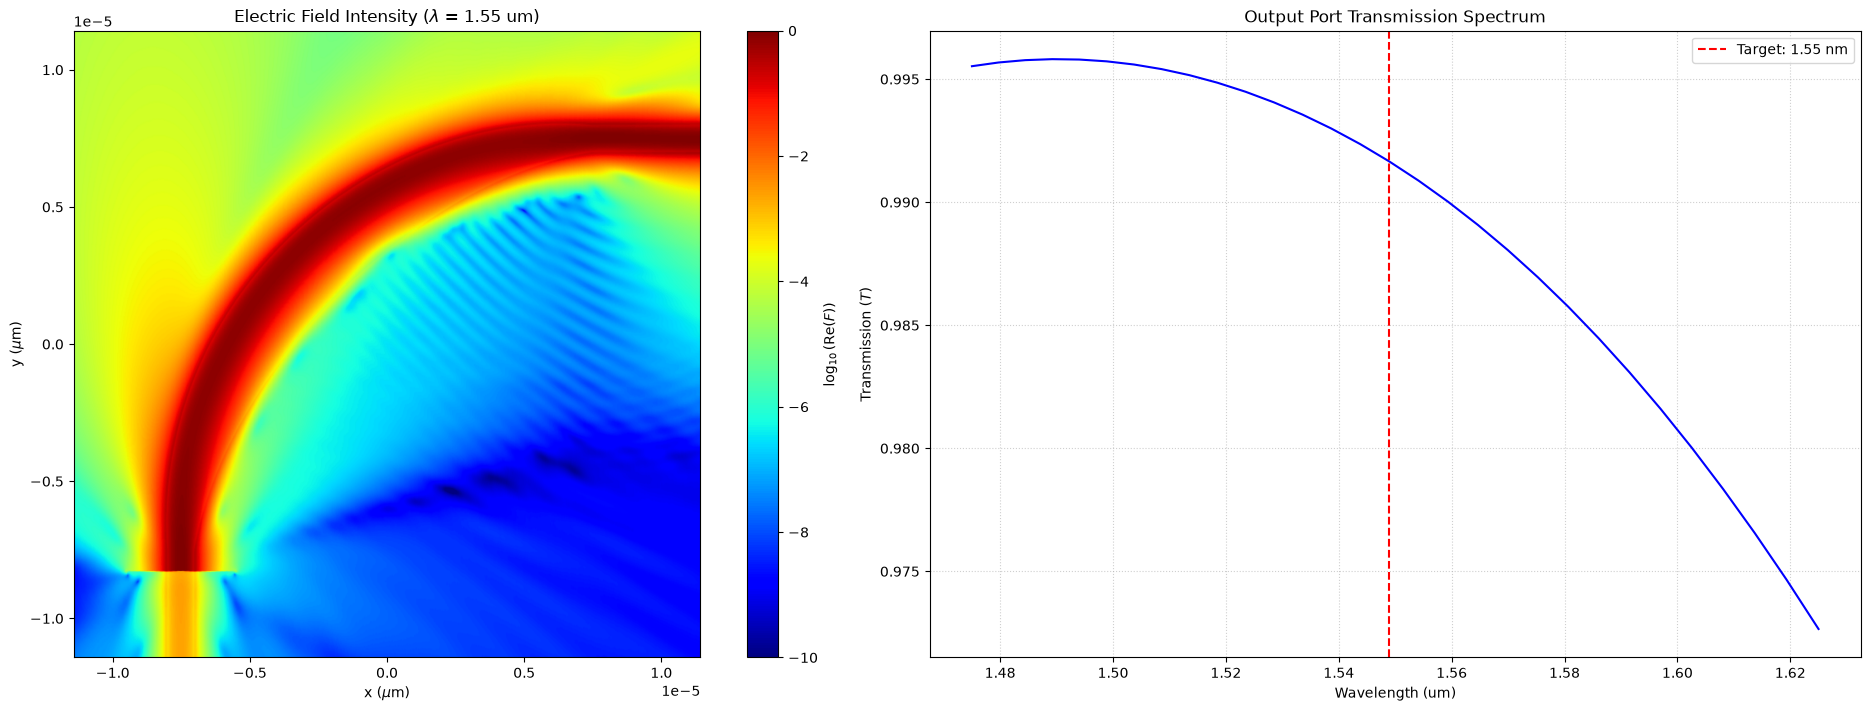

In [21]:
# Best design simulation

solver.switchtolayout()
solver.setnamed("field-monitor", "enabled", True)
solver.setnamed("index-monitor", "enabled", True)
v_best = optimization_data["optimizer"].result[0]
update_90bend(v_best)
solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 7), constrained_layout=True)

T = solver.getresult("FDTD::ports::port-out", "T")

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T = solver.getresult("FDTD::ports::port-out", "T")
wavelengths = np.squeeze(T["lambda"])
transmission = np.squeeze(T["T"])

ax2.plot(wavelengths*1e6, transmission, color='b')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

# Data processing and presentation

In [17]:
# Load results
filename = "results/si3n4_w1000nm_h360nm_90bendGA_s15um_20261121_155105.pkl"

with open(filename, "rb") as f:
    optimization_data = pickle.load(f)

print(f"Data loaded from {filename}")

Data loaded from results/si3n4_w1000nm_h360nm_90bendGA_s15um_20261121_155105.pkl


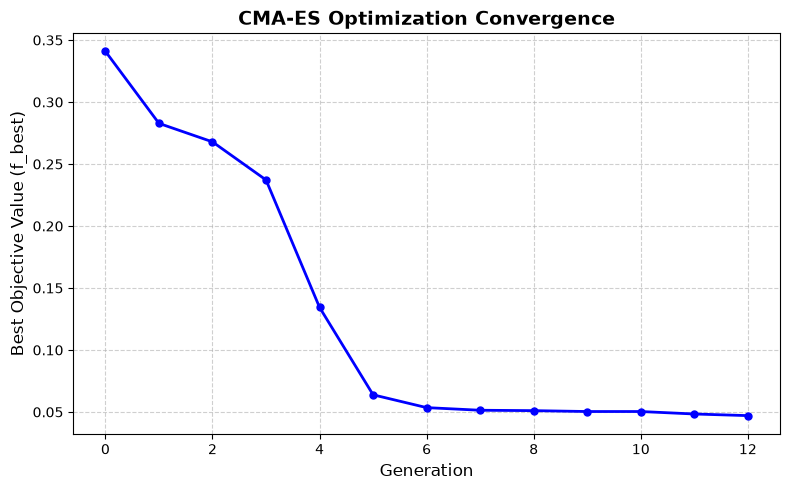

In [18]:
# Optimization history
generations = [gen["gen"] for gen in optimization_data["generations"]]
best_fitness_values = [gen["f_best"] for gen in optimization_data["generations"]]

plt.figure(figsize=(8, 5))
plt.plot(generations, best_fitness_values, marker='o', linestyle='-', color='b', linewidth=2, markersize=5)

plt.title("CMA-ES Optimization Convergence", fontsize=14, fontweight='bold')
plt.xlabel("Generation", fontsize=12)
plt.ylabel("Best Objective Value (f_best)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [22]:
# GDS export
PDK.activate()
gf.clear_cache()
 
c = gf.Component("90-bend")
 
# Geometry
vertices = solver.getnamed("90-bend", "vertices") * 1e6
c.add_polygon(vertices, layer=(1, 0))
 
# Ports
port_in = ((-bend_size/2) * 1e6, (-bend_size/2) * 1e6)
c.add_port(
    name="opt_in",
    center=port_in,
    width=core_width * 1e6,
    orientation=180,
    layer=(1, 0)
)
port_out = ((bend_size/2) * 1e6, (bend_size/2) * 1e6)
c.add_port(
    name="opt_out",
    center=port_out,
    width=core_width * 1e6,
    orientation=0,
    layer=(1, 0)
)
 
gds_filename = f"results/{experiment_name}.gds"
c.write_gds(gds_filename)
print(f"Exported GDS file to: {gds_filename}")

Exported GDS file to: results/si3n4_w1000nm_h360nm_90bendGA_s15um.gds
